# Crack / no-crack classifier for concrete inspection photos

**Team:** Ugo, Alvaro, Sneha
**Course:** AI Methods I  Day 4: Neural networks and computer vision (IAAC MaAI 2026/27)
**Track:** A2  image classifier (ResNet18 pretrained on ImageNet, fine-tuned)
**Model on Hugging Face:**  https://huggingface.co/iaac-maai/day4-<team>-crack-classifier

---

## 0. Introduction and problem definition

### The three questions

**Who would use this model, and for what?**
A facility manager or inspection engineer screening a few thousand close-up photos of concrete walls, to decide which photos an engineer should look at first before a site visit.

**What does a mistake cost?**
A **missed crack** (false negative) can mean a structural problem goes unchecked. A **false alarm** (false positive) costs an engineer about a minute to dismiss. Missed cracks are much more expensive, so we care most about **recall on the `crack` class**, and we are willing to lose some precision for it.

**What would be good enough?**
 Clearly better than the **majority-class baseline** (always predict one class: 50% accuracy, since the classes are balanced), with crack recall ≥ 95% on the test set. We also compare a frozen backbone with a partly fine-tuned one.

### The data

| | |
|---|---|
| **Name** | Concrete Crack Images for Classification (METU) |
| **Source** | Özgenel, Ç. F. (2019), Mendeley Data, DOI [10.17632/5y9wdsg2zt.2](https://data.mendeley.com/datasets/5y9wdsg2zt) – also mirrored on Kaggle |
| **Licence** | CC BY 4.0 (derived models allowed, with attribution) |
| **Size** | 40,000 RGB images, 227 × 227 px: 20,000 `Positive` (crack), 20,000 `Negative` (no crack) |
| **Origin** | Patches cut from 458 high-resolution photos (4032 × 3024) of concrete surfaces on METU campus buildings |
| **One example** | One 227 × 227 close-up image of a concrete surface, with one label: crack or no crack |

 **Known issue we must keep in mind:** the 40,000 patches come from only 458 photos, and the filenames do not tell us which photo a patch came from. We **cannot split by source**, so patches of the same wall can end up in both training and test sets. The test score will probably be **optimistic**. We test the model on our own photos (section 7) to see how it does on images it has really never seen.

In [3]:
%pip install torch torchvision scikit-learn pandas matplotlib kagglehub huggingface_hub

  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-macosx_11_0_arm64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.5/138.5 MB 4.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 6.3 MB/s eta 0:00:00a 0:00:01
Using cached huggingface_hub-2.4.0-py3-none-any.whl (857 kB)
Using cached click-8.5.1-py3-none-any.whl (

In [4]:
# Imports and settings
import copy
import random
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

# Paths: the notebook lives in notebook/, so everything else is one level up
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
for d in (DATA_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Reproducibility: one seed everywhere
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# TRAIN = False skips training and downloads our published weights instead
# (for anyone without the time or a GPU to retrain).
TRAIN = True
HF_REPO = "iaac-maai/day4-<team>-crack-classifier"   # ✏️ your model repository

# How many images per class we sample from the 20,000 available (keeps CPU training to minutes)
N_PER_CLASS = 2000

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__)

device: mps | torch 2.15.0


In [5]:
# Helper: save every figure to figures/ and, if it is a model-card figure, also to models/
def save_fig(fig, name, model_card=False):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    if model_card:
        fig.savefig(MODEL_DIR / name.split("_", 1)[1], dpi=150, bbox_inches="tight")  # drops the "01_" prefix
    print("saved", name)

## 1. Data and splits

### 1.1 Download

The notebook downloads the dataset itself (nothing in `data/` is committed). We use the Kaggle mirror of the METU dataset through `kagglehub`.


In [ ]:
RAW_DIR = DATA_DIR / "raw"
KAGGLE_SLUG = "arunrk7/surface-crack-detection"   #  check: Kaggle mirror of the METU dataset


def find_class_dirs(root):
    # Returns the Positive/ and Negative/ folders anywhere below root, or None.
    root = Path(root)
    pos = next(root.rglob("Positive"), None) if root.exists() else None
    neg = next(root.rglob("Negative"), None) if root.exists() else None
    return (pos, neg) if pos and neg else None


dirs = find_class_dirs(RAW_DIR)
if dirs is None:
    try:
        import kagglehub
        dirs = find_class_dirs(kagglehub.dataset_download(KAGGLE_SLUG))
    except Exception as e:
        print("Automatic download failed:", e)
if dirs is None:
    raise FileNotFoundError("Put the dataset in data/raw/ (with Positive/ and Negative/ folders) and rerun.")

POS_DIR, NEG_DIR = dirs
print("crack images:   ", len(list(POS_DIR.glob("*.jpg"))), "in", POS_DIR)
print("no-crack images:", len(list(NEG_DIR.glob("*.jpg"))), "in", NEG_DIR)

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 233M/233M [00:24<00:00, 10.1MB/s] 

Extracting files...


crack images:    20000 in /Users/snehashenoy/.cache/kagglehub/datasets/arunrk7/surface-crack-detection/versions/1/Positive
no-crack images: 20000 in /Users/snehashenoy/.cache/kagglehub/datasets/arunrk7/surface-crack-detection/versions/1/Negative


### 1.2 Split before anything else

We sample `N_PER_CLASS` images per class, then split them **70 / 15 / 15** into training, validation and test sets, **stratified by class**, with a fixed seed. The test set is used **once**, in section 6.

The images are copied into one folder per class, so that `torchvision.datasets.ImageFolder` can read them:
`data/images/{train,val,test}/{crack,no_crack}/`.

`ImageFolder` sorts class names alphabetically, so **class 0 = `crack`, class 1 = `no_crack`**. This order goes in the model card.

In [10]:
rng = random.Random(SEED)
files = ([(p, "crack") for p in rng.sample(sorted(POS_DIR.glob("*.jpg")), N_PER_CLASS)] +
         [(p, "no_crack") for p in rng.sample(sorted(NEG_DIR.glob("*.jpg")), N_PER_CLASS)])
df = pd.DataFrame(files, columns=["path", "label"])

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

IMG_DIR = DATA_DIR / "images"
if IMG_DIR.exists():
    shutil.rmtree(IMG_DIR)          # start clean, so a rerun gives exactly the same split
for split, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for path, label in zip(part["path"], part["label"]):
        out = IMG_DIR / split / label
        out.mkdir(parents=True, exist_ok=True)
        shutil.copy(path, out / Path(path).name)

pd.DataFrame({s: p["label"].value_counts() for s, p in
              [("train", train_df), ("val", val_df), ("test", test_df)]})

,train,val,test
label,,,
crack,1400,300,300
no_crack,1400,300,300


### 1.3 Look at the data

A few images per class.  What do you notice: surface textures, lighting, how thin the cracks are, anything that could confuse the model (stains, joints, shadows)?

saved 01_sample_grid.png


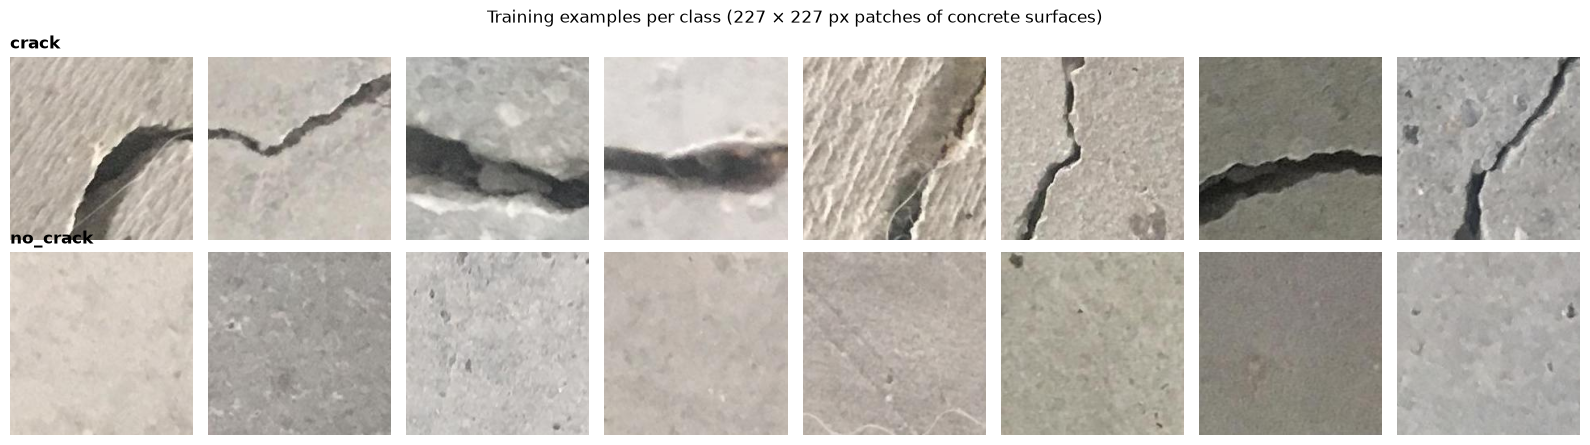

In [11]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for row, label in enumerate(["crack", "no_crack"]):
    sample = train_df[train_df["label"] == label].sample(8, random_state=SEED)
    for ax, path in zip(axes[row], sample["path"]):
        ax.imshow(Image.open(path))
        ax.axis("off")
    axes[row, 0].set_title(label, loc="left", fontsize=12, fontweight="bold")
fig.suptitle("Training examples per class (227 × 227 px patches of concrete surfaces)")
plt.tight_layout()
save_fig(fig, "01_sample_grid.png")
plt.show()

### 1.4 Datasets, transforms and loaders

- **Evaluation transforms:** exactly the preprocessing ResNet18 was pretrained with (`weights.transforms()`: resize, crop to 224 × 224, normalise with ImageNet statistics). **The same transforms must be used at prediction time**, otherwise the model gets inputs it has never seen.
- **Training transforms:** the same, plus random changes (augmentation) so the model does not memorise exact pixels. Cracks can run in any direction, so we also add vertical flips and 90° rotations.

In [12]:
weights = models.ResNet18_Weights.DEFAULT
eval_tf = weights.transforms()
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(eval_tf.mean, eval_tf.std),
])

train_ds = datasets.ImageFolder(IMG_DIR / "train", transform=train_tf)
val_ds = datasets.ImageFolder(IMG_DIR / "val", transform=eval_tf)
test_ds = datasets.ImageFolder(IMG_DIR / "test", transform=eval_tf)
CLASSES = train_ds.classes
CRACK = CLASSES.index("crack")
print("classes (output order):", CLASSES)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=g)
val_loader = DataLoader(val_ds, batch_size=64)     # shuffle=False: order matches val_ds.samples
test_loader = DataLoader(test_ds, batch_size=64)

classes (output order): ['crack', 'no_crack']


## 2. Baseline

**Majority class:** always predict the most common class in the training set. The classes are balanced, so it gets about 50% accuracy. If it always predicts `no_crack`, its crack recall is **0%**: it never finds a single crack. Any useful model must beat this by a wide margin.

In [13]:
majority = train_df["label"].mode()[0]
y_val = np.array([y for _, y in val_ds.samples])
y_base = np.full_like(y_val, CLASSES.index(majority))

base_acc = (y_base == y_val).mean()
base_p, base_r, _, _ = precision_recall_fscore_support(y_val, y_base, labels=[CRACK],
                                                       zero_division=0)
print(f"majority class: {majority}")
print(f"baseline on validation: accuracy {base_acc:.1%}, crack recall {base_r[0]:.1%}")

majority class: crack
baseline on validation: accuracy 50.0%, crack recall 100.0%


## 3. The model and its training

**Transfer learning:** ResNet18 pretrained on ImageNet (1.2 million everyday photos) already knows how to detect edges, lines and textures. We **freeze** all its layers and replace only the last layer (`fc`) with a new one that has 2 outputs, one per class. Only this new layer learns.

**Training loop:** as in notebook 01, extended to record training and validation loss and accuracy per epoch, with **early stopping** (stop when the validation loss has not improved for `patience` epochs, and keep the best weights).

**A detail that matters:** ResNet has *BatchNorm* layers that update their running statistics whenever the model is in `train()` mode, even if their weights are frozen. With a frozen backbone we keep those layers in `eval()` mode, so the pretrained features do not drift.

In [14]:
def build_model(n_classes=2):
    # ResNet18 pretrained on ImageNet, all layers frozen, new trainable last layer.
    model = models.resnet18(weights=weights)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    return model.to(DEVICE)


def set_train_mode(model, train, freeze_bn):
    model.train(train)
    if train and freeze_bn:
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()


def run_epoch(model, loader, loss_fn, optimizer=None, freeze_bn=True):
    train = optimizer is not None
    set_train_mode(model, train, freeze_bn)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = loss_fn(out, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def train_model(model, optimizer, epochs, patience=3, freeze_bn=True):
    loss_fn = nn.CrossEntropyLoss()
    history, best_loss, best_state, wait = [], float("inf"), None, 0
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, loss_fn, optimizer, freeze_bn)
        va_loss, va_acc = run_epoch(model, val_loader, loss_fn)
        history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss,
                            train_acc=tr_acc, val_acc=va_acc))
        print(f"epoch {epoch:2d}  train loss {tr_loss:.3f} acc {tr_acc:.1%}  |  "
              f"val loss {va_loss:.3f} acc {va_acc:.1%}")
        if va_loss < best_loss:
            best_loss, best_state, wait = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print(f"early stopping: no improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)          # keep the weights with the lowest validation loss
    minutes = (time.time() - start) / 60
    print(f"training time: {minutes:.1f} min")
    return pd.DataFrame(history), minutes


model = build_model(len(CLASSES))
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: {n_total:,} total, {n_train:,} trainable")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/snehashenoy/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:08<00:00, 5.52MB/s]


parameters: 11,177,538 total, 1,026 trainable


In [15]:
if TRAIN:
    torch.manual_seed(SEED)
    model = build_model(len(CLASSES))
    optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
    hist_frozen, time_frozen = train_model(model, optimizer, epochs=15, patience=3, freeze_bn=True)
    model_frozen = model
else:
    from huggingface_hub import hf_hub_download
    model_frozen = build_model(len(CLASSES))
    model_frozen.load_state_dict(torch.load(hf_hub_download(HF_REPO, "model.pt"), map_location=DEVICE))
    hist_frozen = None
    print("loaded published weights; training curves are only available with TRAIN = True")

epoch  1  train loss 0.218 acc 93.2%  |  val loss 0.087 acc 98.5%
epoch  2  train loss 0.064 acc 99.0%  |  val loss 0.052 acc 99.5%
epoch  3  train loss 0.048 acc 99.0%  |  val loss 0.040 acc 99.3%
epoch  4  train loss 0.033 acc 99.3%  |  val loss 0.034 acc 99.3%
epoch  5  train loss 0.028 acc 99.4%  |  val loss 0.028 acc 99.5%
epoch  6  train loss 0.021 acc 99.8%  |  val loss 0.026 acc 99.7%
epoch  7  train loss 0.021 acc 99.4%  |  val loss 0.024 acc 99.5%
epoch  8  train loss 0.020 acc 99.5%  |  val loss 0.022 acc 99.7%
epoch  9  train loss 0.020 acc 99.4%  |  val loss 0.020 acc 99.7%
epoch 10  train loss 0.016 acc 99.6%  |  val loss 0.019 acc 99.7%
epoch 11  train loss 0.017 acc 99.5%  |  val loss 0.017 acc 99.7%
epoch 12  train loss 0.016 acc 99.6%  |  val loss 0.016 acc 99.7%
epoch 13  train loss 0.013 acc 99.6%  |  val loss 0.016 acc 99.7%
epoch 14  train loss 0.014 acc 99.6%  |  val loss 0.015 acc 99.7%
epoch 15  train loss 0.012 acc 99.7%  |  val loss 0.015 acc 99.7%
training t

### 3.1 Training curves

✏️ **Read them:** is the model still learning at the last epoch? Is there a gap between training and validation (overfitting)? When would you stop? Note: training accuracy can be *lower* than validation accuracy here, because training images are augmented (harder) and validation images are not.

saved 02_training_curves.png


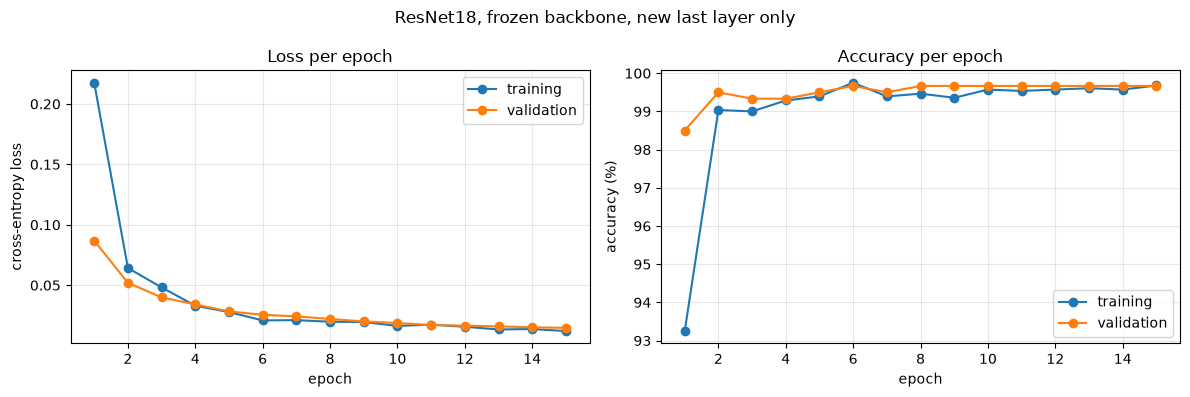

In [16]:
def plot_curves(hist, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(hist["epoch"], hist["train_loss"], "o-", label="training")
    ax1.plot(hist["epoch"], hist["val_loss"], "o-", label="validation")
    ax1.set(title="Loss per epoch", xlabel="epoch", ylabel="cross-entropy loss")
    ax2.plot(hist["epoch"], hist["train_acc"] * 100, "o-", label="training")
    ax2.plot(hist["epoch"], hist["val_acc"] * 100, "o-", label="validation")
    ax2.set(title="Accuracy per epoch", xlabel="epoch", ylabel="accuracy (%)")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    return fig


if hist_frozen is not None:
    fig = plot_curves(hist_frozen, "ResNet18, frozen backbone, new last layer only")
    save_fig(fig, "02_training_curves.png", model_card=True)
    plt.show()

## 4. Look inside and diagnose

### 4.1 Confusion matrix on validation

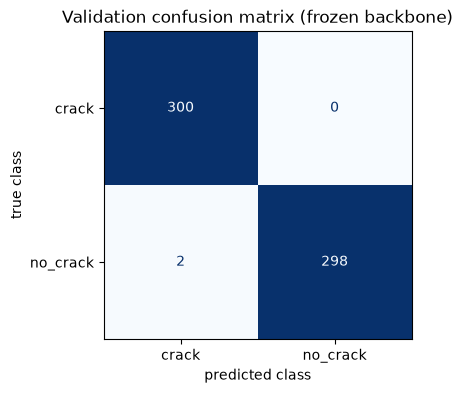

              precision    recall  f1-score   support

       crack      0.993     1.000     0.997       300
    no_crack      1.000     0.993     0.997       300

    accuracy                          0.997       600
   macro avg      0.997     0.997     0.997       600
weighted avg      0.997     0.997     0.997       600



In [17]:
@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probs, labels = [], []
    for xb, yb in loader:
        probs.append(torch.softmax(model(xb.to(DEVICE)), dim=1).cpu())
        labels.append(yb)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()


val_probs, val_labels = predict_probs(model_frozen, val_loader)
val_pred = val_probs.argmax(1)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(val_labels, val_pred), display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Validation confusion matrix (frozen backbone)",
       xlabel="predicted class", ylabel="true class")
plt.show()
print(classification_report(val_labels, val_pred, target_names=CLASSES, digits=3))

### 4.2 Gallery of mistakes

Every misclassified validation image, with the predicted class and its probability.

✏️ **What do the mistakes have in common?** (Write this in your own words, it is graded under *Understanding*.) Things to look for: very thin hairline cracks, stains or dark lines that look like cracks, joints between panels, rough or pitted surfaces, blur, very dark or very bright images. Are the **missed cracks** different from the **false alarms**?

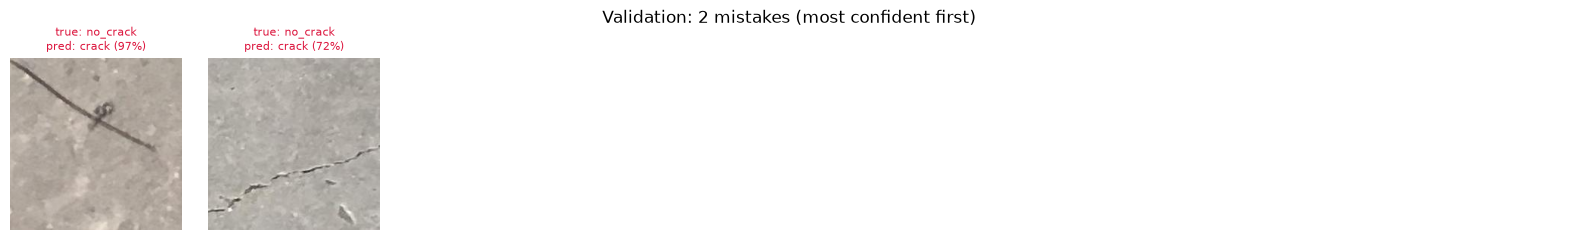

In [18]:
def mistake_gallery(probs, labels, dataset, title, max_n=16):
    pred = probs.argmax(1)
    wrong = np.where(pred != labels)[0]
    # most confident mistakes first: these are the most worrying ones
    wrong = wrong[np.argsort(-probs[wrong, pred[wrong]])][:max_n]
    if len(wrong) == 0:
        print("no mistakes to show")
        return None
    cols = 8
    rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2.4 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(Image.open(dataset.samples[i][0]))
        ax.set_title(f"true: {CLASSES[labels[i]]}\npred: {CLASSES[pred[i]]} ({probs[i, pred[i]]:.0%})",
                     fontsize=8, color="crimson")
    fig.suptitle(f"{title}: {len(np.where(pred != labels)[0])} mistakes (most confident first)")
    plt.tight_layout()
    return fig


fig = mistake_gallery(val_probs, val_labels, val_ds, "Validation")
plt.show()

## 5. Tuning: frozen backbone vs. fine-tuning the last block

**One change:** starting from the trained frozen model, we also unfreeze the last block of ResNet18 (`layer4`) and train it with a **10× smaller learning rate** (1e-4) than the new layer (1e-3), so the pretrained filters are adjusted gently rather than overwritten. BatchNorm in `layer4` is now allowed to update.

We compare both on the **validation set** only. ✏️ Is the gain worth the extra training time and the extra risk of overfitting? A small gain at 3× the time is a perfectly honest finding.

epoch  1  train loss 0.115 acc 97.9%  |  val loss 0.031 acc 99.0%
epoch  2  train loss 0.056 acc 98.7%  |  val loss 0.043 acc 99.5%
epoch  3  train loss 0.020 acc 99.4%  |  val loss 0.009 acc 99.7%
epoch  4  train loss 0.024 acc 99.3%  |  val loss 0.026 acc 99.5%
epoch  5  train loss 0.024 acc 99.4%  |  val loss 0.008 acc 99.5%
epoch  6  train loss 0.009 acc 99.8%  |  val loss 0.015 acc 99.7%
epoch  7  train loss 0.006 acc 99.8%  |  val loss 0.028 acc 99.7%
epoch  8  train loss 0.006 acc 99.8%  |  val loss 0.016 acc 99.5%
early stopping: no improvement for 3 epochs
training time: 1.9 min


,model,val accuracy,crack precision,crack recall,crack F1,trainable params,training time (min)
0,frozen backbone,99.7%,99.3%,100.0%,99.7%,1026,2.700000
1,+ layer4 fine-tuned,99.5%,99.7%,99.3%,99.5%,8394754,4.500000


saved 03_finetune_curves.png


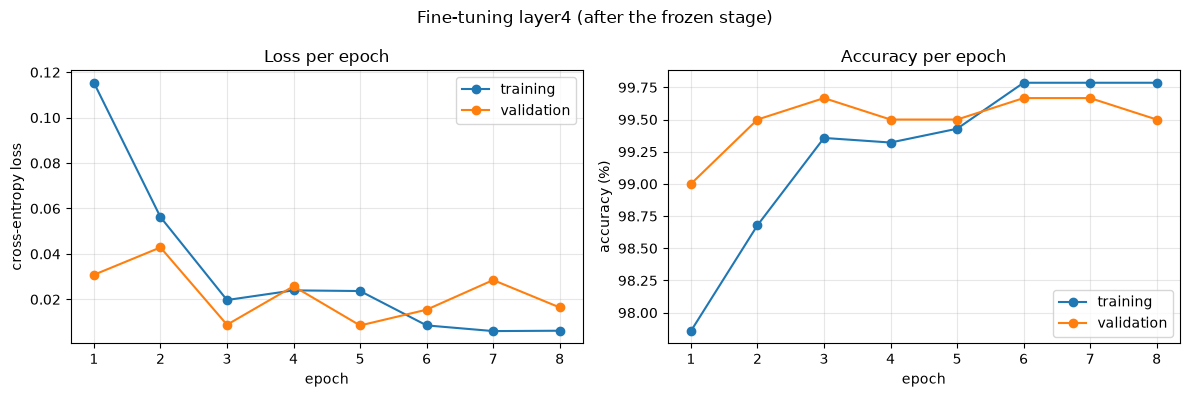

In [19]:
if TRAIN:
    torch.manual_seed(SEED)
    model_ft = copy.deepcopy(model_frozen)
    for p in model_ft.layer4.parameters():
        p.requires_grad = True
    optimizer = torch.optim.Adam([
        {"params": model_ft.layer4.parameters(), "lr": 1e-4},
        {"params": model_ft.fc.parameters(), "lr": 1e-3},
    ])
    hist_ft, time_ft = train_model(model_ft, optimizer, epochs=8, patience=3, freeze_bn=False)

    rows = []
    for name, m, t in [("frozen backbone", model_frozen, time_frozen),
                       ("+ layer4 fine-tuned", model_ft, time_frozen + time_ft)]:
        p, y = predict_probs(m, val_loader)
        prec, rec, f1, _ = precision_recall_fscore_support(y, p.argmax(1), labels=[CRACK])
        rows.append({"model": name, "val accuracy": (p.argmax(1) == y).mean(),
                     "crack precision": prec[0], "crack recall": rec[0], "crack F1": f1[0],
                     "trainable params": sum(q.numel() for q in m.parameters() if q.requires_grad),
                     "training time (min)": round(t, 1)})
    experiments = pd.DataFrame(rows)
    display(experiments.style.format({c: "{:.1%}" for c in
                                      ["val accuracy", "crack precision", "crack recall", "crack F1"]}))

    fig = plot_curves(hist_ft, "Fine-tuning layer4 (after the frozen stage)")
    save_fig(fig, "03_finetune_curves.png")
    plt.show()

✏️ **Choose the final model** based on the validation table (not the test set!) and the cost of mistakes: if both are close, prefer higher **crack recall**, then the simpler model. Set `FINAL` below.

In [20]:
FINAL = "frozen"     # ✏️ "frozen" or "finetuned", based on the validation table above
final_model = model_ft if (TRAIN and FINAL == "finetuned") else model_frozen
print("final model:", FINAL)

final model: frozen


### 5.1 Choosing a decision threshold (on validation)

By default the model says "crack" when P(crack) > 0.5. Because a missed crack costs more than a false alarm, a **lower** threshold may be better: it flags more photos (more false alarms) but misses fewer cracks. We pick the threshold on the **validation** set and only apply it to the test set in section 6.

saved 04_threshold_sweep.png


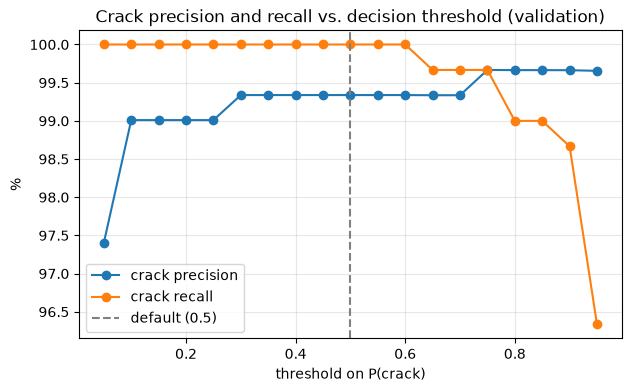

In [21]:
val_probs, val_labels = predict_probs(final_model, val_loader)
is_crack = (val_labels == CRACK)
sweep = []
for t in np.arange(0.05, 0.96, 0.05):
    flag = val_probs[:, CRACK] >= t
    tp, fp, fn = (flag & is_crack).sum(), (flag & ~is_crack).sum(), (~flag & is_crack).sum()
    sweep.append({"threshold": t, "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)})
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["threshold"], sweep["precision"] * 100, "o-", label="crack precision")
ax.plot(sweep["threshold"], sweep["recall"] * 100, "o-", label="crack recall")
ax.axvline(0.5, color="grey", ls="--", label="default (0.5)")
ax.set(title="Crack precision and recall vs. decision threshold (validation)",
       xlabel="threshold on P(crack)", ylabel="%")
ax.legend()
ax.grid(alpha=0.3)
save_fig(fig, "04_threshold_sweep.png", model_card=True)
plt.show()

THRESHOLD = 0.5      # ✏️ choose from the plot, e.g. the highest threshold that keeps crack recall >= 99%

## 6. Test set, once

This is the first and only time we use the test set. ✏️ Compare with the baseline, and remember the warning from section 0: patches from the same photo may be in both training and test, so this number is likely optimistic.

,model,accuracy,crack precision,crack recall,crack F1
0,baseline (always 'crack'),50.0%,50.0%,100.0%,66.7%
1,"ResNet18 frozen, threshold 0.5",99.7%,99.7%,99.7%,99.7%


              precision    recall  f1-score   support

       crack      0.997     0.997     0.997       300
    no_crack      0.997     0.997     0.997       300

    accuracy                          0.997       600
   macro avg      0.997     0.997     0.997       600
weighted avg      0.997     0.997     0.997       600

saved 05_confusion_matrix.png


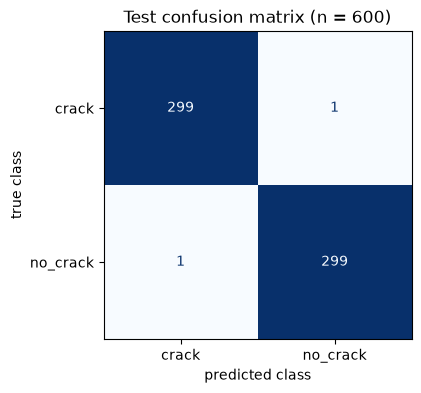

In [22]:
test_probs, test_labels = predict_probs(final_model, test_loader)
test_pred = np.where(test_probs[:, CRACK] >= THRESHOLD, CRACK, 1 - CRACK)

y_base_test = np.full_like(test_labels, CLASSES.index(majority))
results = []
for name, pred in [(f"baseline (always '{majority}')", y_base_test),
                   (f"ResNet18 {FINAL}, threshold {THRESHOLD}", test_pred)]:
    prec, rec, f1, _ = precision_recall_fscore_support(test_labels, pred, labels=[CRACK], zero_division=0)
    results.append({"model": name, "accuracy": (pred == test_labels).mean(),
                    "crack precision": prec[0], "crack recall": rec[0], "crack F1": f1[0]})
results = pd.DataFrame(results)
display(results.style.format({c: "{:.1%}" for c in results.columns[1:]}))
print(classification_report(test_labels, test_pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(test_labels, test_pred), display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set(title=f"Test confusion matrix (n = {len(test_labels)})",
       xlabel="predicted class", ylabel="true class")
save_fig(fig, "05_confusion_matrix.png", model_card=True)
plt.show()

saved 06_model_vs_baseline.png


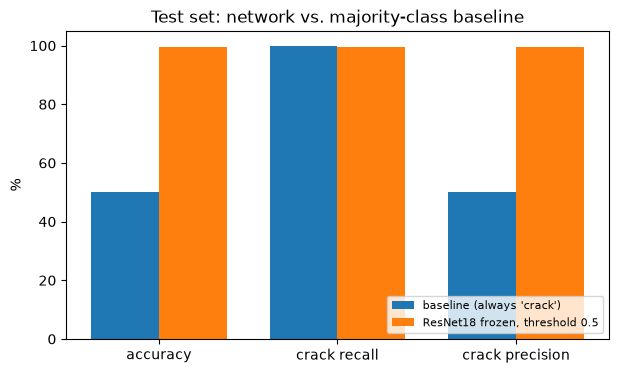

In [23]:
# Model vs. baseline, as a bar chart
fig, ax = plt.subplots(figsize=(7, 4))
metrics = ["accuracy", "crack recall", "crack precision"]
x = np.arange(len(metrics))
for i, row in results.iterrows():
    ax.bar(x + (i - 0.5) * 0.38, [row[m] * 100 for m in metrics], width=0.38, label=row["model"])
ax.set_xticks(x, metrics)
ax.set(title="Test set: network vs. majority-class baseline", ylabel="%", ylim=(0, 105))
ax.legend(loc="lower right", fontsize=8)
save_fig(fig, "06_model_vs_baseline.png", model_card=True)
plt.show()

### 6.1 What the model does: test predictions, including mistakes

A grid of test images with the true class, the predicted class and the probability. Mistakes are included on purpose (red titles).

saved 07_predictions.png


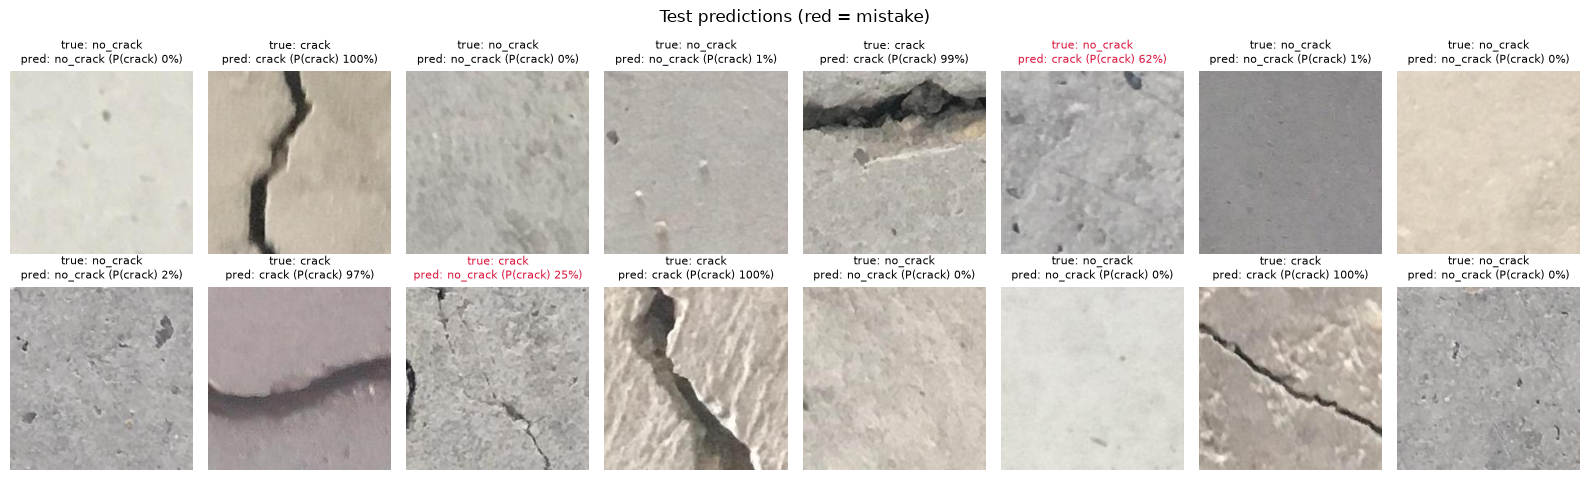

saved 08_failures.png


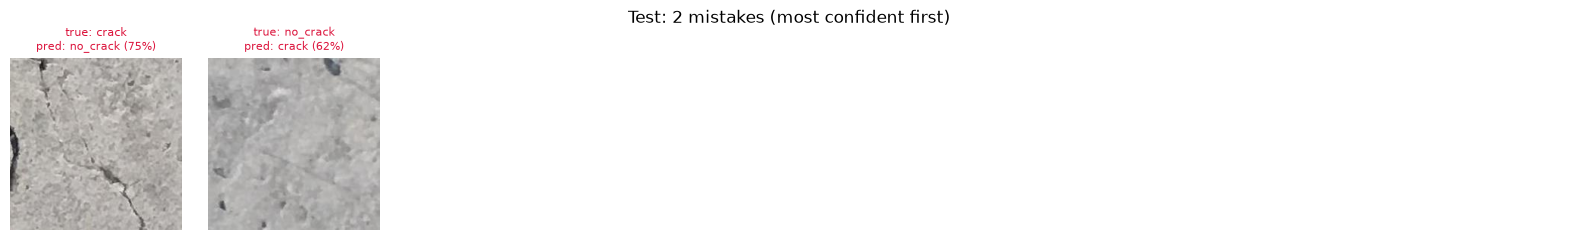

In [24]:
pred_test = test_pred
wrong = np.where(pred_test != test_labels)[0]
right = np.where(pred_test == test_labels)[0]
rng_np = np.random.default_rng(SEED)
show = np.concatenate([rng_np.choice(wrong, min(4, len(wrong)), replace=False),
                       rng_np.choice(right, 16 - min(4, len(wrong)), replace=False)])
rng_np.shuffle(show)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, i in zip(axes.flat, show):
    ax.imshow(Image.open(test_ds.samples[i][0]))
    ax.axis("off")
    ok = pred_test[i] == test_labels[i]
    ax.set_title(f"true: {CLASSES[test_labels[i]]}\npred: {CLASSES[pred_test[i]]} "
                 f"(P(crack) {test_probs[i, CRACK]:.0%})", fontsize=8, color="black" if ok else "crimson")
fig.suptitle("Test predictions (red = mistake)")
plt.tight_layout()
save_fig(fig, "07_predictions.png", model_card=True)
plt.show()

fig = mistake_gallery(test_probs, test_labels, test_ds, "Test")
if fig is not None:
    save_fig(fig, "08_failures.png", model_card=True)
    plt.show()

## 7. Application: ranking new photos to check first

We run the model on **our own photos** of concrete surfaces, taken around ✏️ (place, date, phone model). These images are not part of the dataset, so this is the real test of whether the model is useful.

**How to prepare the photos:** the model was trained on close-ups (each patch shows roughly a 10–20 cm area of wall). Take close-ups, or crop your photos to a similar scale, and save them as `.jpg` in `data/own_photos/`. Optionally, name them `crack_01.jpg`, `nocrack_01.jpg`… so we can count how many the model gets right. ✏️ Check that no people or number plates are visible.

The output is a **ranking**: photos sorted by P(crack), so an inspector checks the most likely cracks first.

In [25]:
OWN_DIR = DATA_DIR / "own_photos"
own = sorted(list(OWN_DIR.glob("*.jpg")) + list(OWN_DIR.glob("*.jpeg")) + list(OWN_DIR.glob("*.png")))

if not own:
    print(f"No photos found in {OWN_DIR.resolve()}: add some and rerun this cell.")
else:
    final_model.eval()
    with torch.no_grad():
        batch = torch.stack([eval_tf(Image.open(p).convert("RGB")) for p in own]).to(DEVICE)
        p_crack = torch.softmax(final_model(batch), dim=1)[:, CRACK].cpu().numpy()
    ranking = (pd.DataFrame({"photo": [p.name for p in own], "P(crack)": p_crack})
               .sort_values("P(crack)", ascending=False).reset_index(drop=True))
    ranking["flag"] = np.where(ranking["P(crack)"] >= THRESHOLD, "CHECK", "")
    display(ranking.style.format({"P(crack)": "{:.1%}"}))

    # If the filenames say the true class, measure accuracy on our own photos
    truth = ranking["photo"].str.lower().map(
        lambda n: "crack" if n.startswith("crack") else "no_crack" if n.startswith("nocrack") else None)
    if truth.notna().any():
        pred_own = np.where(ranking["P(crack)"] >= THRESHOLD, "crack", "no_crack")
        known = truth.notna()
        print(f"accuracy on our own labelled photos: {(pred_own[known] == truth[known]).mean():.0%} "
              f"(n = {known.sum()})")

    n = min(len(ranking), 16)
    cols = min(n, 8)
    fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(2.2 * cols, 2.6 * np.ceil(n / cols)),
                             squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for rank, (ax, (_, r)) in enumerate(zip(axes.flat, ranking.head(n).iterrows()), start=1):
        ax.imshow(Image.open(OWN_DIR / r["photo"]))
        ax.set_title(f"#{rank}  P(crack) {r['P(crack)']:.0%}", fontsize=8,
                     color="crimson" if r["flag"] else "black")
    fig.suptitle("Our own photos, ranked by probability of a crack (red = flagged to check)")
    plt.tight_layout()
    save_fig(fig, "09_own_photos_ranking.png", model_card=True)
    plt.show()

No photos found in /Users/snehashenoy/data/own_photos: add some and rerun this cell.


✏️ **Read the result:** does the model do as well on our photos as on the test set? If not, why (different concrete, lighting, camera, scale, plaster vs. bare concrete)? This gap is probably the most important limitation of the model.

## 8. Save, reload and use

We save only the weights (`state_dict`). To load them, a user must first build exactly the same architecture: ResNet18 with a new 2-output last layer. This code goes in the model card.

In [26]:
if TRAIN:
    torch.save(final_model.state_dict(), MODEL_DIR / "model.pt")
    print("saved", MODEL_DIR / "model.pt",
          f"({(MODEL_DIR / 'model.pt').stat().st_size / 1e6:.1f} MB)")

saved ../models/model.pt (44.8 MB)


In [27]:
# Reload into a NEW object, as a user would, and predict one test image
reloaded = models.resnet18()                                    # architecture only, no pretrained weights
reloaded.fc = nn.Linear(reloaded.fc.in_features, len(CLASSES))
weights_file = MODEL_DIR / "model.pt"
if not weights_file.exists():                                   # TRAIN = False: use the published weights
    from huggingface_hub import hf_hub_download
    weights_file = hf_hub_download(HF_REPO, "model.pt")
reloaded.load_state_dict(torch.load(weights_file, map_location="cpu"))
reloaded.eval()

transform = models.ResNet18_Weights.DEFAULT.transforms()        # the same preprocessing as in training
path, true_idx = test_ds.samples[0]
image = Image.open(path).convert("RGB")
with torch.no_grad():
    probabilities = torch.softmax(reloaded(transform(image).unsqueeze(0)), dim=1)[0]

print("image:", Path(path).name, "| true class:", CLASSES[true_idx])
print({c: round(p, 3) for c, p in zip(CLASSES, probabilities.tolist())})

image: 00014.jpg | true class: crack
{'crack': 1.0, 'no_crack': 0.0}


In [28]:
# Library versions, for the model card
import sys
import torchvision
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print("model card figures in models/:", sorted(p.name for p in MODEL_DIR.glob("*.png")))

Python 3.11.12 | torch 2.15.0 | torchvision 0.29.2
model card figures in models/: ['confusion_matrix.png', 'failures.png', 'model_vs_baseline.png', 'predictions.png', 'threshold_sweep.png', 'training_curves.png']


## 9. Conclusions

### Key findings
✏️ 3–6 bullet points **with numbers**, for example:
- On the test set the model reaches **…% accuracy** and **…% crack recall**, against 50% / 0% for the majority-class baseline.
- Fine-tuning `layer4` changed validation accuracy from …% to …%, for … × the training time; we kept the … model because …
- With a threshold of …, the model misses … of … cracks and raises … false alarms per 100 photos.
- Most mistakes are … (hairline cracks / stains / joints / dark images …).
- On our own photos it reached …% (n = …), much lower / similar, because …

### Limitations and biases
✏️ For example:
- **Optimistic test score:** patches of the same photo can be in both training and test (no source information in the dataset).
- **Narrow data:** one campus in Turkey, bare concrete surfaces, close-up patches. Unknown performance on plaster, brick, painted walls, other climates, or drone images.
- **Scale:** it classifies one close-up patch; it cannot find a crack in a whole-facade photo (that would be detection, Track B).
- **No severity:** it says *whether* there is a crack, not how wide, deep or dangerous it is.
- **Not for:** structural safety decisions without an engineer; any decision about people.